# Emotion Classification

|Nama | NRP|
|---|---|
|Fa'iz Akbar Hizbullah | 5054241005|
|Shabrina Sarayati | 5054241009|
|Sultan Hamdi Jailani Daulay | 5054241013|
|Muhammad Dayyan Ghazanfar Latief | 5054241036|
|Sitti Aminah | 5054241041|

- Sequence: FastText + RNN family
- Numeric: orthographic + punctuation markers + InSet + emoticon features


In [1]:
import gc
import json
import os
import random
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from gensim.models import FastText
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import Callback, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Bidirectional, Concatenate, Dense, Dropout, Embedding, GRU, Input, LSTM, SimpleRNN
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from wordcloud import STOPWORDS, WordCloud

try:
    from tqdm.keras import TqdmCallback
except Exception:
    TqdmCallback = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


2026-04-25 16:38:39.949457: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777135120.171027      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777135120.241337      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777135120.722111      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777135120.722162      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777135120.722165      23 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
MAX_WORDS = 20000
MAX_LEN = 50
EMBED_DIM = 300
BATCH_SIZE = 64
EPOCHS = 30
PATIENCE = 2
LR = 5e-4
WEIGHT_DECAY = 1e-4
CLIPNORM = 1.0
PAPER_MACRO_F1 = 0.6973
RUN_CV = True
CV_MODELS = ["BiGRU", "BiLSTM", "GRU", "LSTM"]
CV_FOLDS = 5
CV_EPOCHS = 20

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

VECTOR_ROOT = Path("/kaggle/input/datasets/paibarrr/fasttext-vector")
DATA_PATH = Path("/kaggle/input/datasets/sultandaulay/merged-emotion-dataset/merged_emotion_dataset_V2.csv")
SLANG_PATH = Path("/kaggle/input/datasets/dennisherdi/indonesian-twitter-emotion/kamus_singkatan.csv")
PRETRAINED_VEC_PATH = VECTOR_ROOT / "cc.id.300.vec"

OUTPUT_ROOT = Path("/kaggle/working")
ARTIFACT_DIR = OUTPUT_ROOT / "artifacts_rnn"
MODEL_DIR = ARTIFACT_DIR / "models"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.19.0
GPU available: True


In [3]:
df = pd.read_csv(DATA_PATH)
slang_df = pd.read_csv(SLANG_PATH, sep=";", header=None, names=["slang", "formal"])
slang_df["slang"] = slang_df["slang"].astype(str).str.lower().str.strip()
slang_df["formal"] = slang_df["formal"].astype(str).str.lower().str.strip()
slang_dict = dict(zip(slang_df["slang"], slang_df["formal"]))

display(df.head())
print("Shape:", df.shape)
print("Null total:", df.isnull().sum().sum())


,tweet,label,source
0,"Baca replyan Iim jadi mikir lagi, nabung bulan...",sadness,original
1,baru kali ini ke [USERNAME] Gancit dan kecewa ...,anger,original
2,@femalebodybuil6 She can join together with li...,happy,original
3,banyak kendala ini itu & harus masuk semester ...,fear,original
4,@Beruang2026 @InFebriyan128 Pengen bgt nanjak ...,fear,original


Shape: (6223, 3)
Null total: 0


## EDA


,count,pct
label,,
happy,2180,35.03
anger,1386,22.27
sadness,1018,16.36
fear,837,13.45
love,802,12.89


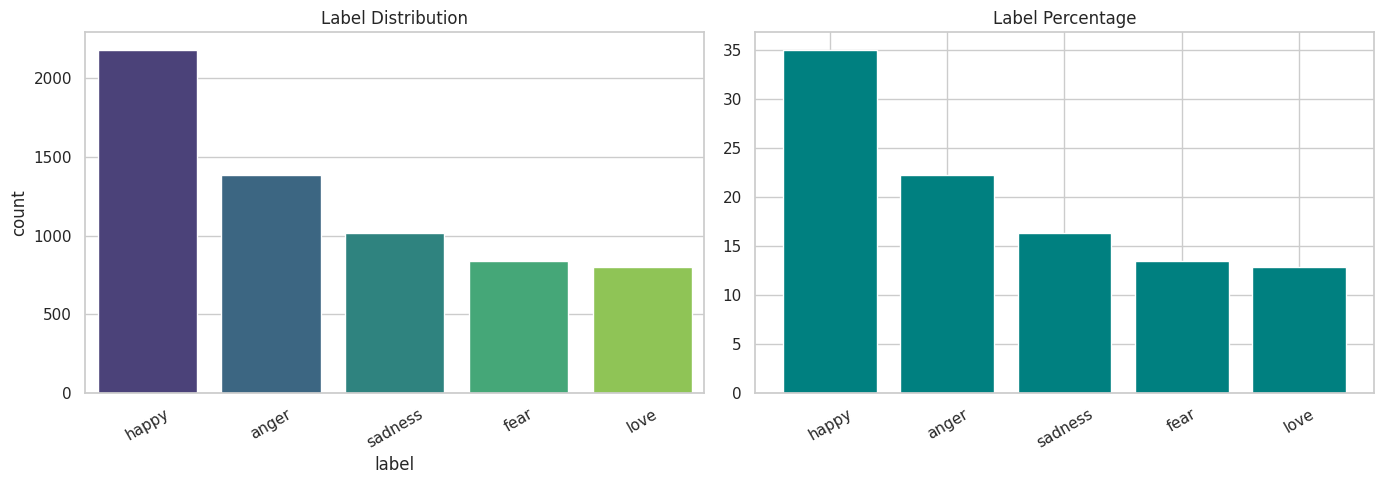

,word,count
0,dan,1788
1,di,1764
2,[username],1754
3,yg,1730
4,yang,1728
5,aku,1329
6,itu,968
7,ada,961
8,happy,949
9,ini,938


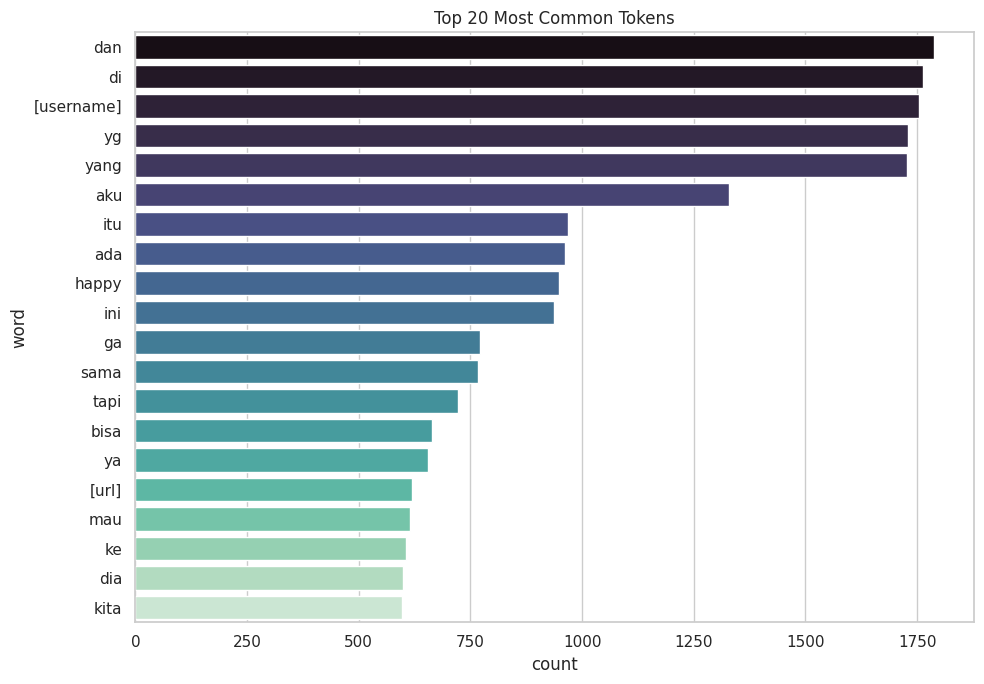

In [4]:
label_count = df["label"].value_counts()
label_pct = (label_count / label_count.sum() * 100).round(2)
display(pd.DataFrame({"count": label_count, "pct": label_pct}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="label", order=label_count.index, ax=axes[0], palette="viridis")
axes[0].set_title("Label Distribution")
axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(label_pct.index, label_pct.values, color="teal")
axes[1].set_title("Label Percentage")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

df["tmp_tokens"] = df["tweet"].astype(str).str.lower().str.split()
common_tokens = Counter([tok for row in df["tmp_tokens"] for tok in row]).most_common(20)
common_df = pd.DataFrame(common_tokens, columns=["word", "count"])
display(common_df)

plt.figure(figsize=(10, 7))
sns.barplot(data=common_df, x="count", y="word", palette="mako")
plt.title("Top 20 Most Common Tokens")
plt.tight_layout()
plt.show()


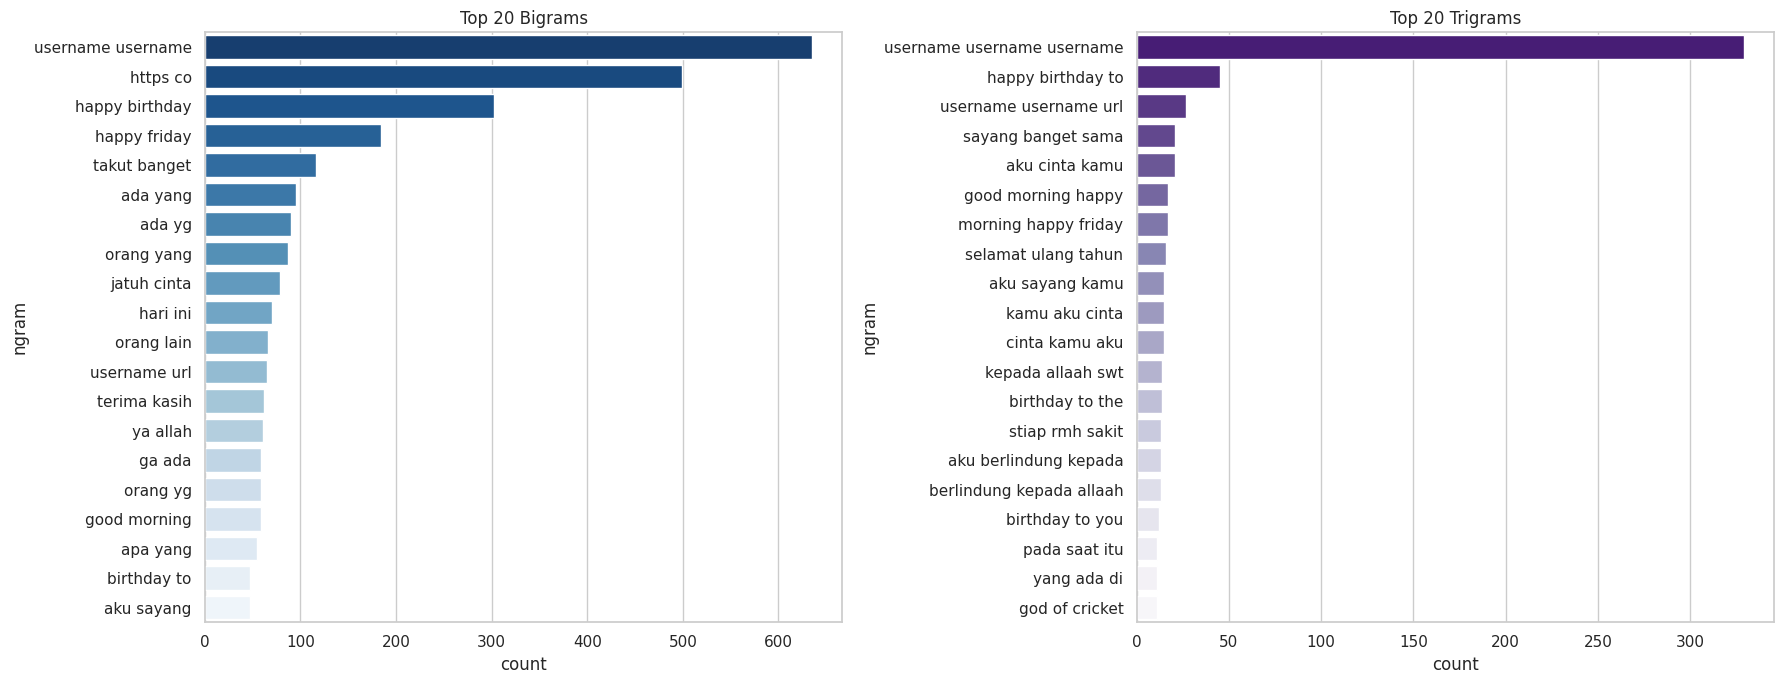

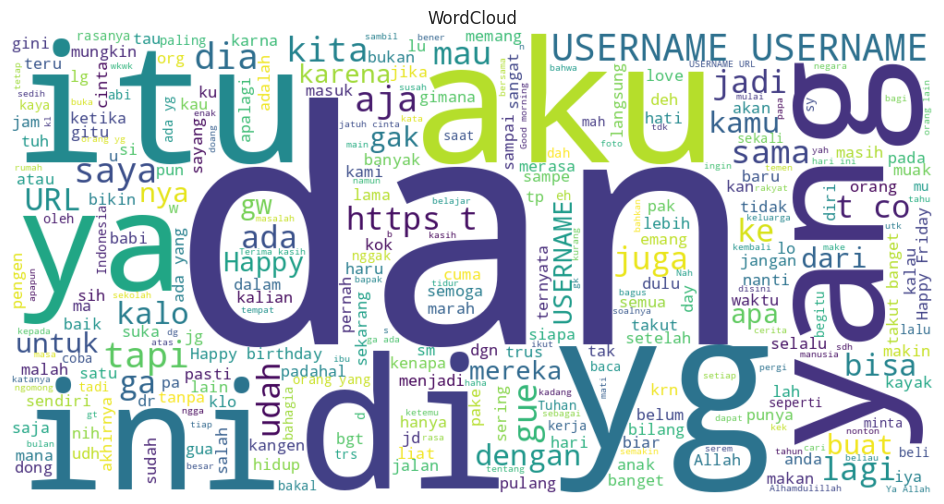

In [5]:
def get_top_ngrams(corpus, n_words=2, top_n=20):
    vec = CountVectorizer(ngram_range=(n_words, n_words))
    bag = vec.fit_transform(corpus)
    sum_words = np.asarray(bag.sum(axis=0)).ravel()
    words_freq = [(word, sum_words[idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)[:top_n]
    return pd.DataFrame(words_freq, columns=["ngram", "count"])

corpus = df["tweet"].astype(str).dropna().tolist()
bigram_df = get_top_ngrams(corpus, n_words=2, top_n=20)
trigram_df = get_top_ngrams(corpus, n_words=3, top_n=20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.barplot(data=bigram_df, x="count", y="ngram", ax=axes[0], palette="Blues_r")
axes[0].set_title("Top 20 Bigrams")
sns.barplot(data=trigram_df, x="count", y="ngram", ax=axes[1], palette="Purples_r")
axes[1].set_title("Top 20 Trigrams")
plt.tight_layout()
plt.show()

wc = WordCloud(width=1000, height=500, background_color="white", stopwords=set(STOPWORDS), max_words=300).generate(" ".join(df["tweet"].astype(str)))
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud")
plt.show()


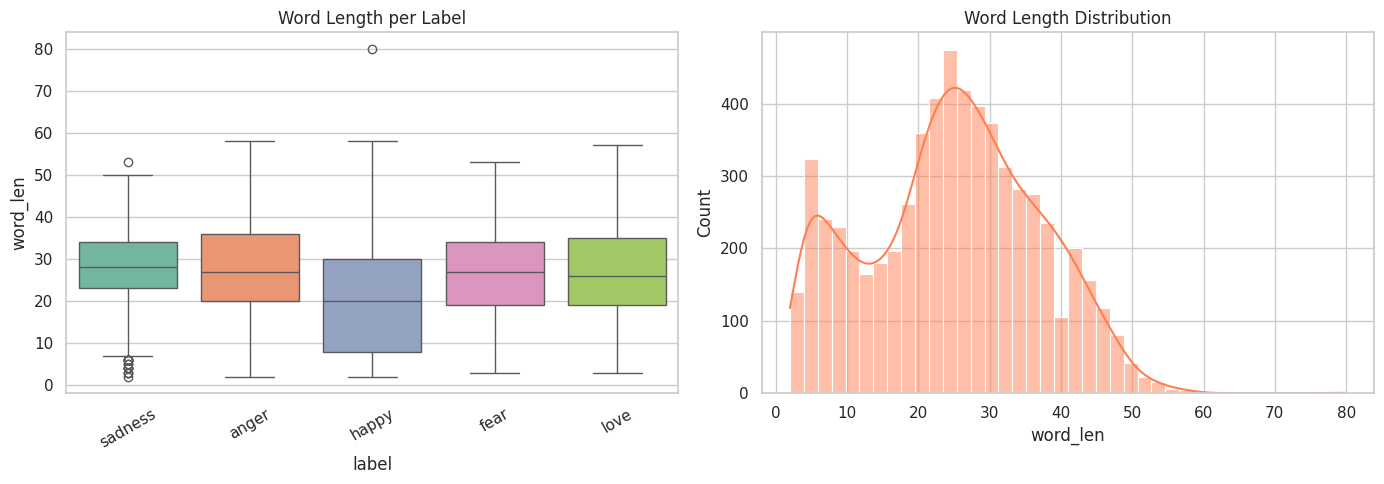

In [6]:
df["char_len"] = df["tweet"].astype(str).str.len()
df["word_len"] = df["tmp_tokens"].str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="label", y="word_len", ax=axes[0], palette="Set2")
axes[0].set_title("Word Length per Label")
axes[0].tick_params(axis="x", rotation=30)

sns.histplot(df["word_len"], bins=40, kde=True, ax=axes[1], color="coral")
axes[1].set_title("Word Length Distribution")
plt.tight_layout()
plt.show()


## Preprocessing


In [7]:
INSET_POS_URL = "https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv"
INSET_NEG_URL = "https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv"

def load_inset():
    try:
        pos_df = pd.read_csv(INSET_POS_URL, sep="\t")
        neg_df = pd.read_csv(INSET_NEG_URL, sep="\t")
        pos_df.columns = [c.strip().lower() for c in pos_df.columns]
        neg_df.columns = [c.strip().lower() for c in neg_df.columns]
        pos_dict = dict(zip(pos_df["word"].astype(str), pos_df["weight"].astype(float)))
        neg_dict = dict(zip(neg_df["word"].astype(str), neg_df["weight"].astype(float)))
        print("InSet loaded:", len(pos_dict), "positive |", len(neg_dict), "negative")
        return pos_dict, neg_dict
    except Exception as e:
        print("InSet load failed, fallback to empty dict:", e)
        return {}, {}

inset_pos, inset_neg = load_inset()

SEED_POS_EMOTICONS = {":)", ":-)", ":D", ":-D", ";)", ";-)", "^_^", "<3", "xD"}
SEED_NEG_EMOTICONS = {":(", ":-(", ":'(", "T_T", "-_-", "._.", "):", "):<", ":'-("}

def discover_emoticons(texts, min_freq=2):
    pat = re.compile(r"(?:(?:[:;=xX8]['\-^]?[)(DPpOo/|])|(?:[)(][:'\-^]?(?:[:;=xX8]))|(?:[Tt]\_?[Tt])|(?:\^_\^)|(?:<_3|<3)|(?::\)+|:\(+))")
    counter = Counter()
    for t in texts:
        raw = str(t)
        found = pat.findall(raw)
        for e in found:
            counter[e] += 1

    auto_pos = set()
    auto_neg = set()
    for emo, c in counter.items():
        if c < min_freq:
            continue
        s = emo.lower()
        if any(k in s for k in [":)", ":-)", ";)", ";-)", ":d", "xd", "<3", "^_^"]):
            auto_pos.add(emo)
        elif any(k in s for k in [":(", ":-(", "):", "t_t", ":'(", ":-("]):
            auto_neg.add(emo)

    return counter, auto_pos, auto_neg


InSet loaded: 3609 positive | 6607 negative


In [8]:
def clean_text_keep_markers(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@[^\s]+", " ", text)
    text = re.sub(r"#([^\s]+)", " ", text)
    text = re.sub(r"((\\x[a-z0-9]{1,}){1,})", " ", text)
    text = re.sub(r"username|url|sensitive-no|askmf", " ", text)
    text = text.replace("!", " __excl__ ")
    text = text.replace("?", " __ques__ ")
    text = re.sub(r"[^a-z_\s]", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def normalize_slang(text, mapper):
    return " ".join([mapper.get(tok, tok) for tok in text.split()])

def preprocess_text(text):
    return normalize_slang(clean_text_keep_markers(text), slang_dict)

def build_aux_features(raw_texts, clean_texts):
    rows = []
    for raw, clean in zip(raw_texts, clean_texts):
        raw = str(raw)
        clean = str(clean)
        raw_lower = raw.lower()
        tokens = clean.split()
        lex_tokens = [t for t in tokens if t not in {"__excl__", "__ques__"}]

        exclam_count = raw.count("!")
        question_count = raw.count("?")
        upper_count = sum(1 for ch in raw if ch.isupper())
        alpha_count = sum(1 for ch in raw if ch.isalpha())
        upper_ratio = upper_count / max(alpha_count, 1)
        char_len = len(raw)
        word_len = len(lex_tokens)
        marker_excl = tokens.count("__excl__")
        marker_ques = tokens.count("__ques__")
        emot_pos = len(EMO_POS_PATTERN.findall(raw_lower))
        emot_neg = len(EMO_NEG_PATTERN.findall(raw_lower))
        inset_pos_score = float(sum(inset_pos.get(t, 0.0) for t in lex_tokens))
        inset_neg_score = float(sum(abs(inset_neg.get(t, 0.0)) for t in lex_tokens))
        inset_pos_hits = float(sum(1 for t in lex_tokens if t in inset_pos))
        inset_neg_hits = float(sum(1 for t in lex_tokens if t in inset_neg))

        rows.append([
            exclam_count, question_count, upper_count, upper_ratio, char_len, word_len,
            marker_excl, marker_ques, emot_pos, emot_neg,
            inset_pos_score, inset_neg_score, inset_pos_hits, inset_neg_hits
        ])

    return np.asarray(rows, dtype=np.float32)

AUX_FEATURE_NAMES = [
    "exclam_count", "question_count", "upper_count", "upper_ratio", "char_len", "word_len",
    "marker_excl", "marker_ques", "emot_pos", "emot_neg",
    "inset_pos_score", "inset_neg_score", "inset_pos_hits", "inset_neg_hits"
]


In [9]:
work_df = df[["tweet", "label"]].copy()
work_df["clean_tweet"] = work_df["tweet"].astype(str).apply(preprocess_text)
work_df = work_df[work_df["clean_tweet"].str.len() > 0].drop_duplicates(subset=["clean_tweet", "label"]).reset_index(drop=True)

label_encoder = LabelEncoder()
work_df["label_id"] = label_encoder.fit_transform(work_df["label"])
num_classes = len(label_encoder.classes_)

X_train_df, X_val_df, y_train, y_val = train_test_split(
    work_df[["tweet", "clean_tweet"]],
    work_df["label_id"].values,
    test_size=0.2,
    random_state=SEED,
    stratify=work_df["label_id"].values,
)

X_train_raw = X_train_df["tweet"].astype(str).tolist()
X_val_raw = X_val_df["tweet"].astype(str).tolist()
X_train_text = X_train_df["clean_tweet"].astype(str).tolist()
X_val_text = X_val_df["clean_tweet"].astype(str).tolist()

print("Train/Val:", len(X_train_text), len(X_val_text))
print("Classes:", list(label_encoder.classes_))


Train/Val: 4742 1186
Classes: ['anger', 'fear', 'happy', 'love', 'sadness']


In [10]:
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<UNK>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post")

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
unk_idx = tokenizer.word_index.get("<UNK>", 1)

def oov_ratio(seqs, idx):
    total = sum(len(s) for s in seqs)
    oov = sum(sum(1 for t in s if t == idx) for s in seqs)
    return (oov / max(total, 1)) * 100

print("Vocab size:", vocab_size)
print("OOV train/val: {:.2f}% | {:.2f}%".format(oov_ratio(X_train_seq, unk_idx), oov_ratio(X_val_seq, unk_idx)))


Vocab size: 18030
OOV train/val: 0.00% | 9.95%


In [11]:
emo_counter, auto_pos, auto_neg = discover_emoticons(X_train_raw, min_freq=2)
POS_EMOTICONS = sorted(set(SEED_POS_EMOTICONS).union(auto_pos))
NEG_EMOTICONS = sorted(set(SEED_NEG_EMOTICONS).union(auto_neg))

if POS_EMOTICONS:
    EMO_POS_PATTERN = re.compile("|".join(re.escape(e) for e in POS_EMOTICONS))
else:
    EMO_POS_PATTERN = re.compile(r"$^")
if NEG_EMOTICONS:
    EMO_NEG_PATTERN = re.compile("|".join(re.escape(e) for e in NEG_EMOTICONS))
else:
    EMO_NEG_PATTERN = re.compile(r"$^")

print("Detected emoticon patterns:", len(emo_counter))
print("POS emoticons:", len(POS_EMOTICONS), "| NEG emoticons:", len(NEG_EMOTICONS))
print("Top discovered emoticons:", emo_counter.most_common(10))


Detected emoticon patterns: 31
POS emoticons: 10 | NEG emoticons: 9
Top discovered emoticons: [('tt', 644), (':/', 370), (':(', 115), (':)', 82), ('xp', 30), (":')", 27), ('TT', 27), ('XO', 17), ('xo', 16), (":'(", 10)]


In [12]:
X_train_aux = build_aux_features(X_train_raw, X_train_text)
X_val_aux = build_aux_features(X_val_raw, X_val_text)

aux_mu = X_train_aux.mean(axis=0)
aux_sigma = X_train_aux.std(axis=0)
aux_sigma[aux_sigma == 0] = 1.0
X_train_aux = (X_train_aux - aux_mu) / aux_sigma
X_val_aux = (X_val_aux - aux_mu) / aux_sigma

AUX_DIM = X_train_aux.shape[1]
display(pd.DataFrame(X_train_aux, columns=AUX_FEATURE_NAMES).describe().T)


,count,mean,std,min,25%,50%,75%,max
exclam_count,4742.0,8.848939e-09,1.000076,-0.248116,-0.248116,-0.248116,-0.248116,18.001543
question_count,4742.0,4.022245e-09,1.000075,-0.296499,-0.296499,-0.296499,-0.296499,14.722389
upper_count,4742.0,1.608898e-08,1.000116,-0.575495,-0.465193,-0.299739,0.031169,12.219621
upper_ratio,4742.0,1.169669e-06,1.000107,-0.576504,-0.466717,-0.317437,0.021123,5.598972
char_len,4742.0,5.309364e-08,1.000106,-2.169068,-0.601536,0.011227,0.737992,6.309858
word_len,4742.0,-6.073590e-08,1.000109,-1.956277,-0.708060,0.040870,0.706586,4.700879
marker_excl,4742.0,-1.005561e-08,1.000103,-0.247258,-0.247258,-0.247258,-0.247258,18.089844
marker_ques,4742.0,-3.217796e-09,1.000075,-0.296217,-0.296217,-0.296217,-0.296217,14.770287
emot_pos,4742.0,-8.044490e-09,1.000100,-0.119322,-0.119322,-0.119322,-0.119322,26.824665
emot_neg,4742.0,1.850233e-08,1.000117,-0.161360,-0.161360,-0.161360,-0.161360,19.974707


In [13]:
needed_words = {w for w, idx in tokenizer.word_index.items() if 0 < idx < vocab_size}
embedding_matrix = np.zeros((vocab_size, EMBED_DIM), dtype=np.float32)
unk_vector = np.random.normal(loc=0.0, scale=0.05, size=(EMBED_DIM,)).astype(np.float32)
embedding_matrix[unk_idx] = unk_vector

loaded = 0
if PRETRAINED_VEC_PATH.exists():
    with open(PRETRAINED_VEC_PATH, "r", encoding="utf-8", errors="ignore") as f:
        first_line = f.readline().rstrip("\n")
        parts = first_line.split(" ")
        has_header = len(parts) == 2 and parts[0].isdigit() and parts[1].isdigit()
        if not has_header:
            vals = first_line.split()
            if len(vals) == EMBED_DIM + 1 and vals[0] in needed_words:
                embedding_matrix[tokenizer.word_index[vals[0]]] = np.asarray(vals[1:], dtype=np.float32)
                loaded += 1
        for line in f:
            vals = line.rstrip("\n").split(" ")
            if len(vals) != EMBED_DIM + 1:
                continue
            word = vals[0]
            idx = tokenizer.word_index.get(word)
            if idx is None or idx >= vocab_size:
                continue
            embedding_matrix[idx] = np.asarray(vals[1:], dtype=np.float32)
            loaded += 1
    print("Using pretrained vectors from:", PRETRAINED_VEC_PATH)
else:
    sentences_for_ft = [txt.split() for txt in X_train_text]
    ft_model = FastText(vector_size=EMBED_DIM, window=5, min_count=1, workers=os.cpu_count() or 2, sg=1, epochs=15, seed=SEED)
    ft_model.build_vocab(sentences_for_ft)
    ft_model.train(sentences_for_ft, total_examples=len(sentences_for_ft), epochs=ft_model.epochs)
    for word, idx in tokenizer.word_index.items():
        if idx >= vocab_size or idx == 0:
            continue
        try:
            embedding_matrix[idx] = ft_model.wv[word]
            loaded += 1
        except Exception:
            embedding_matrix[idx] = unk_vector
    del ft_model

for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size or idx == 0:
        continue
    if not np.any(embedding_matrix[idx]):
        embedding_matrix[idx] = unk_vector

classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = {int(k): float(v) for k, v in zip(classes, class_weights)}

print("Embedding matrix:", embedding_matrix.shape)
print("Loaded vectors:", loaded)
print("Class weight:", class_weight_dict)


Using pretrained vectors from: /kaggle/input/datasets/paibarrr/fasttext-vector/cc.id.300.vec
Embedding matrix: (18030, 300)
Loaded vectors: 15821
Class weight: {0: 0.8575045207956601, 1: 1.5396103896103897, 2: 0.6013950538998097, 3: 1.4958990536277603, 4: 1.172311495673671}


## Util


In [14]:
results = []
histories = {}
reports = {}
cms = {}

TRAIN_INPUTS = [X_train_pad, X_train_aux]
VAL_INPUTS = [X_val_pad, X_val_aux]

def compile_model(model):
    try:
        loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(label_smoothing=0.05)
    except TypeError:
        loss_fn = "sparse_categorical_crossentropy"
    model.compile(
        optimizer=AdamW(learning_rate=LR, weight_decay=WEIGHT_DECAY, clipnorm=CLIPNORM),
        loss=loss_fn,
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="acc")],
    )
    return model

class ValF1Callback(Callback):
    def __init__(self, val_inputs, y_true, batch_size=256):
        super().__init__()
        self.val_inputs = val_inputs
        self.y_true = y_true
        self.batch_size = batch_size
        self.history = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        y_prob = self.model.predict(self.val_inputs, batch_size=self.batch_size, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        val_f1 = f1_score(self.y_true, y_pred, average="macro")
        self.history.append(float(val_f1))
        logs["val_f1"] = float(val_f1)

def fit_and_evaluate(model, model_name):
    best_path = MODEL_DIR / f"{model_name.lower()}_best.keras"
    final_path = MODEL_DIR / f"{model_name.lower()}_final.keras"
    val_f1_cb = ValF1Callback(VAL_INPUTS, y_val, batch_size=256)
    callbacks = [
        EarlyStopping(monitor="val_f1", mode="max", patience=PATIENCE, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_f1", mode="max", factor=0.5, patience=1, min_lr=1e-6),
        ModelCheckpoint(filepath=str(best_path), monitor="val_f1", mode="max", save_best_only=True),
        val_f1_cb,
    ]
    if TqdmCallback is not None:
        callbacks.append(TqdmCallback(verbose=1))

    history = model.fit(
        TRAIN_INPUTS, y_train,
        validation_data=(VAL_INPUTS, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        verbose=0 if TqdmCallback is not None else 1,
    )
    history.history["val_f1"] = val_f1_cb.history

    y_pred = np.argmax(model.predict(VAL_INPUTS, batch_size=256, verbose=0), axis=1)
    result = {
        "model": model_name,
        "train_loss_last": float(history.history["loss"][-1]),
        "val_loss_last": float(history.history["val_loss"][-1]),
        "val_f1_last": float(history.history["val_f1"][-1]),
        "val_acc_last": float(history.history["val_acc"][-1]),
        "val_acc_eval": float(accuracy_score(y_val, y_pred)),
        "val_macro_f1_eval": float(f1_score(y_val, y_pred, average="macro")),
        "best_model_path": str(best_path),
        "final_model_path": str(final_path),
    }
    report_text = classification_report(y_val, y_pred, target_names=label_encoder.classes_, digits=4, zero_division=0)
    cm = confusion_matrix(y_val, y_pred)
    model.save(final_path)
    return result, history.history, report_text, cm


## Model 1 - RNN


In [15]:
tf.keras.backend.clear_session()
gc.collect()
seq_input = Input(shape=(MAX_LEN,), name="rnn_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="rnn_aux_input")
e = Embedding(vocab_size, EMBED_DIM, weights=[embedding_matrix], trainable=False, mask_zero=True)(seq_input)
x = SimpleRNN(64, dropout=0.2)(e)
x = Dense(96, activation="relu")(x)
x = Dropout(0.3)(x)
z = Dense(32, activation="relu")(aux_input)
z = Dropout(0.1)(z)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(num_classes, activation="softmax")(h)
rnn_model = Model(inputs=[seq_input, aux_input], outputs=out, name="RNN_fusion")
rnn_model = compile_model(rnn_model)
rnn_result, rnn_history, rnn_report, rnn_cm = fit_and_evaluate(rnn_model, "RNN")
results.append(rnn_result); histories["RNN"] = rnn_history; reports["RNN"] = rnn_report; cms["RNN"] = rnn_cm
print(rnn_report)
display(pd.DataFrame([rnn_result]))


I0000 00:00:1777135294.513417      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777135294.519605      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

I0000 00:00:1777135298.869720      75 service.cc:152] XLA service 0x7bebb80de040 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777135298.869754      75 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777135298.869757      75 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777135299.556437      75 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1777135303.168475      75 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


              precision    recall  f1-score   support

       anger     0.6146    0.8809    0.7240       277
        fear     0.6535    0.4286    0.5176       154
       happy     0.8308    0.6853    0.7510       394
        love     0.6603    0.6519    0.6561       158
     sadness     0.4010    0.4089    0.4049       203

    accuracy                         0.6459      1186
   macro avg     0.6320    0.6111    0.6107      1186
weighted avg     0.6610    0.6459    0.6425      1186



,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,RNN,0.550646,1.041903,0.610731,0.645868,0.645868,0.610731,/kaggle/working/artifacts_rnn/models/rnn_best....,/kaggle/working/artifacts_rnn/models/rnn_final...


## Model 2 - LSTM


In [16]:
tf.keras.backend.clear_session()
gc.collect()
seq_input = Input(shape=(MAX_LEN,), name="lstm_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="lstm_aux_input")
e = Embedding(vocab_size, EMBED_DIM, weights=[embedding_matrix], trainable=False, mask_zero=True)(seq_input)
x = LSTM(64, dropout=0.2)(e)
x = Dense(96, activation="relu")(x)
x = Dropout(0.3)(x)
z = Dense(32, activation="relu")(aux_input)
z = Dropout(0.1)(z)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(num_classes, activation="softmax")(h)
lstm_model = Model(inputs=[seq_input, aux_input], outputs=out, name="LSTM_fusion")
lstm_model = compile_model(lstm_model)
lstm_result, lstm_history, lstm_report, lstm_cm = fit_and_evaluate(lstm_model, "LSTM")
results.append(lstm_result); histories["LSTM"] = lstm_history; reports["LSTM"] = lstm_report; cms["LSTM"] = lstm_cm
print(lstm_report)
display(pd.DataFrame([lstm_result]))


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

              precision    recall  f1-score   support

       anger     0.6667    0.8881    0.7616       277
        fear     0.9300    0.6039    0.7323       154
       happy     0.8481    0.7513    0.7968       394
        love     0.7000    0.7975    0.7456       158
     sadness     0.5160    0.4778    0.4962       203

    accuracy                         0.7234      1186
   macro avg     0.7322    0.7037    0.7065      1186
weighted avg     0.7398    0.7234    0.7219      1186



,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,LSTM,0.581761,0.761901,0.706478,0.72344,0.72344,0.706478,/kaggle/working/artifacts_rnn/models/lstm_best...,/kaggle/working/artifacts_rnn/models/lstm_fina...


## Model 3 - BiLSTM


In [17]:
tf.keras.backend.clear_session()
gc.collect()
seq_input = Input(shape=(MAX_LEN,), name="bilstm_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="bilstm_aux_input")
e = Embedding(vocab_size, EMBED_DIM, weights=[embedding_matrix], trainable=False, mask_zero=True)(seq_input)
x = Bidirectional(LSTM(64, dropout=0.2))(e)
x = Dense(96, activation="relu")(x)
x = Dropout(0.3)(x)
z = Dense(32, activation="relu")(aux_input)
z = Dropout(0.1)(z)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(num_classes, activation="softmax")(h)
bilstm_model = Model(inputs=[seq_input, aux_input], outputs=out, name="BiLSTM_fusion")
bilstm_model = compile_model(bilstm_model)
bilstm_result, bilstm_history, bilstm_report, bilstm_cm = fit_and_evaluate(bilstm_model, "BiLSTM")
results.append(bilstm_result); histories["BiLSTM"] = bilstm_history; reports["BiLSTM"] = bilstm_report; cms["BiLSTM"] = bilstm_cm
print(bilstm_report)
display(pd.DataFrame([bilstm_result]))


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

              precision    recall  f1-score   support

       anger     0.6919    0.8592    0.7665       277
        fear     0.8319    0.6104    0.7041       154
       happy     0.8411    0.7792    0.8090       394
        love     0.7097    0.8354    0.7674       158
     sadness     0.5787    0.5074    0.5407       203

    accuracy                         0.7369      1186
   macro avg     0.7306    0.7183    0.7175      1186
weighted avg     0.7426    0.7369    0.7340      1186



,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,BiLSTM,0.431194,0.813045,0.717542,0.736931,0.736931,0.717542,/kaggle/working/artifacts_rnn/models/bilstm_be...,/kaggle/working/artifacts_rnn/models/bilstm_fi...


## Model 4 - GRU


In [18]:
tf.keras.backend.clear_session()
gc.collect()
seq_input = Input(shape=(MAX_LEN,), name="gru_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="gru_aux_input")
e = Embedding(vocab_size, EMBED_DIM, weights=[embedding_matrix], trainable=False, mask_zero=True)(seq_input)
x = GRU(64, dropout=0.2)(e)
x = Dense(96, activation="relu")(x)
x = Dropout(0.3)(x)
z = Dense(32, activation="relu")(aux_input)
z = Dropout(0.1)(z)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(num_classes, activation="softmax")(h)
gru_model = Model(inputs=[seq_input, aux_input], outputs=out, name="GRU_fusion")
gru_model = compile_model(gru_model)
gru_result, gru_history, gru_report, gru_cm = fit_and_evaluate(gru_model, "GRU")
results.append(gru_result); histories["GRU"] = gru_history; reports["GRU"] = gru_report; cms["GRU"] = gru_cm
print(gru_report)
display(pd.DataFrame([gru_result]))


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

              precision    recall  f1-score   support

       anger     0.7033    0.8556    0.7720       277
        fear     0.9008    0.7078    0.7927       154
       happy     0.8453    0.7766    0.8095       394
        love     0.7065    0.8228    0.7602       158
     sadness     0.5549    0.4975    0.5247       203

    accuracy                         0.7445      1186
   macro avg     0.7422    0.7321    0.7318      1186
weighted avg     0.7512    0.7445    0.7433      1186



,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,GRU,0.600591,0.694715,0.731829,0.744519,0.744519,0.731829,/kaggle/working/artifacts_rnn/models/gru_best....,/kaggle/working/artifacts_rnn/models/gru_final...


## Model 5 - BiGRU


In [19]:
tf.keras.backend.clear_session()
gc.collect()
seq_input = Input(shape=(MAX_LEN,), name="bigru_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="bigru_aux_input")
e = Embedding(vocab_size, EMBED_DIM, weights=[embedding_matrix], trainable=False, mask_zero=True)(seq_input)
x = Bidirectional(GRU(64, dropout=0.2))(e)
x = Dense(96, activation="relu")(x)
x = Dropout(0.3)(x)
z = Dense(32, activation="relu")(aux_input)
z = Dropout(0.1)(z)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(num_classes, activation="softmax")(h)
bigru_model = Model(inputs=[seq_input, aux_input], outputs=out, name="BiGRU_fusion")
bigru_model = compile_model(bigru_model)
bigru_result, bigru_history, bigru_report, bigru_cm = fit_and_evaluate(bigru_model, "BiGRU")
results.append(bigru_result); histories["BiGRU"] = bigru_history; reports["BiGRU"] = bigru_report; cms["BiGRU"] = bigru_cm
print(bigru_report)
display(pd.DataFrame([bigru_result]))


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

              precision    recall  f1-score   support

       anger     0.6743    0.8520    0.7528       277
        fear     0.8244    0.7013    0.7579       154
       happy     0.8642    0.7589    0.8081       394
        love     0.7111    0.8101    0.7574       158
     sadness     0.5251    0.4631    0.4921       203

    accuracy                         0.7293      1186
   macro avg     0.7198    0.7171    0.7137      1186
weighted avg     0.7362    0.7293    0.7278      1186



,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,BiGRU,0.448503,0.775148,0.713667,0.729342,0.729342,0.713667,/kaggle/working/artifacts_rnn/models/bigru_bes...,/kaggle/working/artifacts_rnn/models/bigru_fin...


## Model 6 - DeepRNN


In [20]:
tf.keras.backend.clear_session()
gc.collect()
seq_input = Input(shape=(MAX_LEN,), name="deeprnn_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="deeprnn_aux_input")
e = Embedding(vocab_size, EMBED_DIM, weights=[embedding_matrix], trainable=False, mask_zero=True)(seq_input)
x = SimpleRNN(64, return_sequences=True, dropout=0.2)(e)
x = SimpleRNN(32, dropout=0.2)(x)
x = Dense(96, activation="relu")(x)
x = Dropout(0.3)(x)
z = Dense(32, activation="relu")(aux_input)
z = Dropout(0.1)(z)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(num_classes, activation="softmax")(h)
deeprnn_model = Model(inputs=[seq_input, aux_input], outputs=out, name="DeepRNN_fusion")
deeprnn_model = compile_model(deeprnn_model)
deeprnn_result, deeprnn_history, deeprnn_report, deeprnn_cm = fit_and_evaluate(deeprnn_model, "DeepRNN")
results.append(deeprnn_result); histories["DeepRNN"] = deeprnn_history; reports["DeepRNN"] = deeprnn_report; cms["DeepRNN"] = deeprnn_cm
print(deeprnn_report)
display(pd.DataFrame([deeprnn_result]))


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

              precision    recall  f1-score   support

       anger     0.6677    0.8051    0.7300       277
        fear     0.7434    0.5455    0.6292       154
       happy     0.8105    0.7056    0.7544       394
        love     0.5474    0.8038    0.6513       158
     sadness     0.4146    0.3350    0.3706       203

    accuracy                         0.6577      1186
   macro avg     0.6367    0.6390    0.6271      1186
weighted avg     0.6656    0.6577    0.6530      1186



,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,DeepRNN,0.637805,0.976214,0.627086,0.657673,0.657673,0.627086,/kaggle/working/artifacts_rnn/models/deeprnn_b...,/kaggle/working/artifacts_rnn/models/deeprnn_f...


## Validation Evaluation


,model,train_loss_last,val_loss_last,val_f1_last,val_acc_last,val_acc_eval,val_macro_f1_eval,best_model_path,final_model_path
0,GRU,0.600591,0.694715,0.731829,0.744519,0.744519,0.731829,/kaggle/working/artifacts_rnn/models/gru_best....,/kaggle/working/artifacts_rnn/models/gru_final...
1,BiLSTM,0.431194,0.813045,0.717542,0.736931,0.736931,0.717542,/kaggle/working/artifacts_rnn/models/bilstm_be...,/kaggle/working/artifacts_rnn/models/bilstm_fi...
2,BiGRU,0.448503,0.775148,0.713667,0.729342,0.729342,0.713667,/kaggle/working/artifacts_rnn/models/bigru_bes...,/kaggle/working/artifacts_rnn/models/bigru_fin...
3,LSTM,0.581761,0.761901,0.706478,0.723440,0.723440,0.706478,/kaggle/working/artifacts_rnn/models/lstm_best...,/kaggle/working/artifacts_rnn/models/lstm_fina...
4,DeepRNN,0.637805,0.976214,0.627086,0.657673,0.657673,0.627086,/kaggle/working/artifacts_rnn/models/deeprnn_b...,/kaggle/working/artifacts_rnn/models/deeprnn_f...
5,RNN,0.550646,1.041903,0.610731,0.645868,0.645868,0.610731,/kaggle/working/artifacts_rnn/models/rnn_best....,/kaggle/working/artifacts_rnn/models/rnn_final...


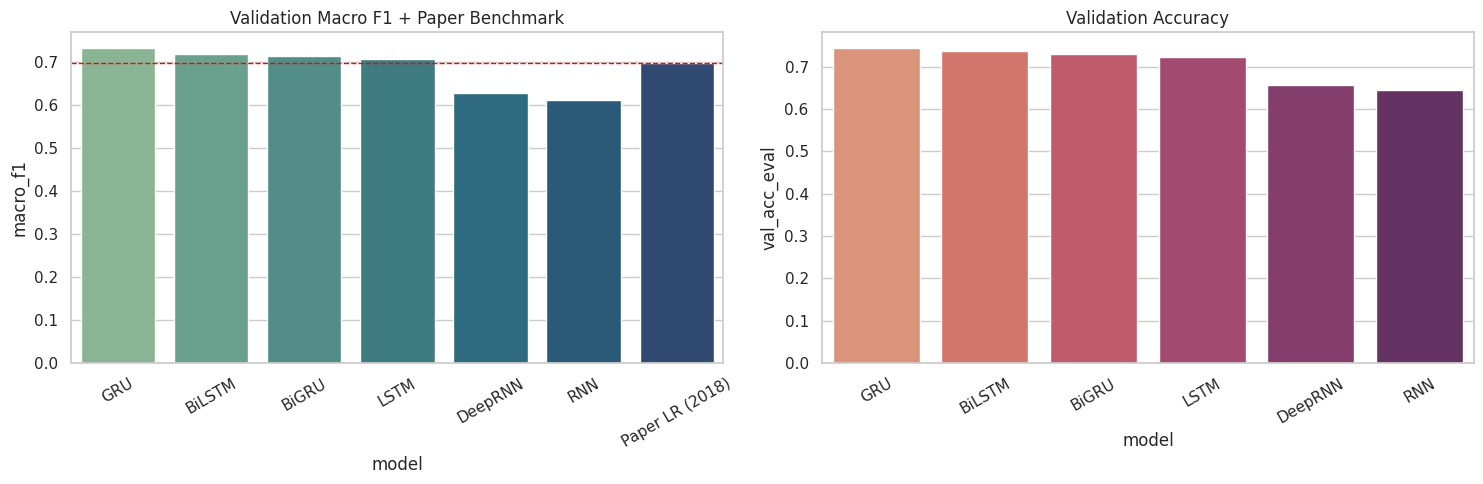

In [21]:
results_df = pd.DataFrame(results).sort_values("val_macro_f1_eval", ascending=False).reset_index(drop=True)
display(results_df)
results_df.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)

plot_df = results_df[["model", "val_macro_f1_eval"]].copy()
plot_df.columns = ["model", "macro_f1"]
paper_row = pd.DataFrame({"model": ["Paper LR (2018)"], "macro_f1": [PAPER_MACRO_F1]})
plot_df = pd.concat([plot_df, paper_row], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=plot_df, x="model", y="macro_f1", ax=axes[0], palette="crest")
axes[0].set_title("Validation Macro F1 + Paper Benchmark")
axes[0].tick_params(axis="x", rotation=30)
axes[0].axhline(PAPER_MACRO_F1, color="red", linestyle="--", linewidth=1)

sns.barplot(data=results_df, x="model", y="val_acc_eval", ax=axes[1], palette="flare")
axes[1].set_title("Validation Accuracy")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


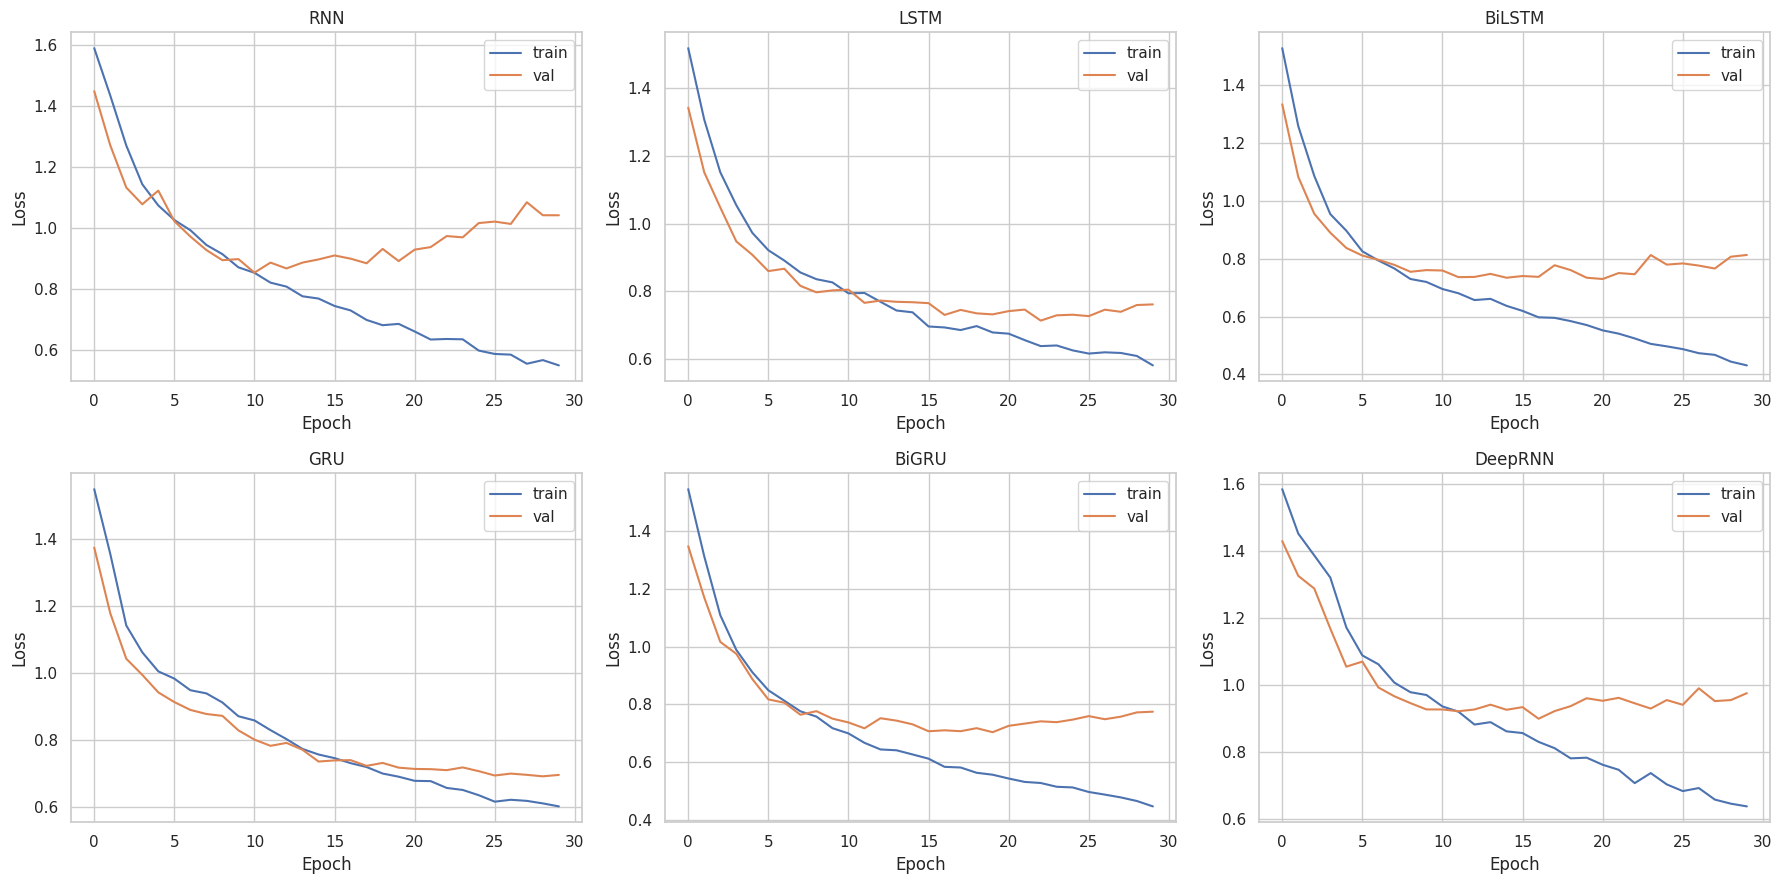

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes[0, 0].plot(histories["RNN"]["loss"], label="train"); axes[0, 0].plot(histories["RNN"]["val_loss"], label="val"); axes[0, 0].set_title("RNN")
axes[0, 1].plot(histories["LSTM"]["loss"], label="train"); axes[0, 1].plot(histories["LSTM"]["val_loss"], label="val"); axes[0, 1].set_title("LSTM")
axes[0, 2].plot(histories["BiLSTM"]["loss"], label="train"); axes[0, 2].plot(histories["BiLSTM"]["val_loss"], label="val"); axes[0, 2].set_title("BiLSTM")
axes[1, 0].plot(histories["GRU"]["loss"], label="train"); axes[1, 0].plot(histories["GRU"]["val_loss"], label="val"); axes[1, 0].set_title("GRU")
axes[1, 1].plot(histories["BiGRU"]["loss"], label="train"); axes[1, 1].plot(histories["BiGRU"]["val_loss"], label="val"); axes[1, 1].set_title("BiGRU")
axes[1, 2].plot(histories["DeepRNN"]["loss"], label="train"); axes[1, 2].plot(histories["DeepRNN"]["val_loss"], label="val"); axes[1, 2].set_title("DeepRNN")
for ax in axes.flatten():
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.show()


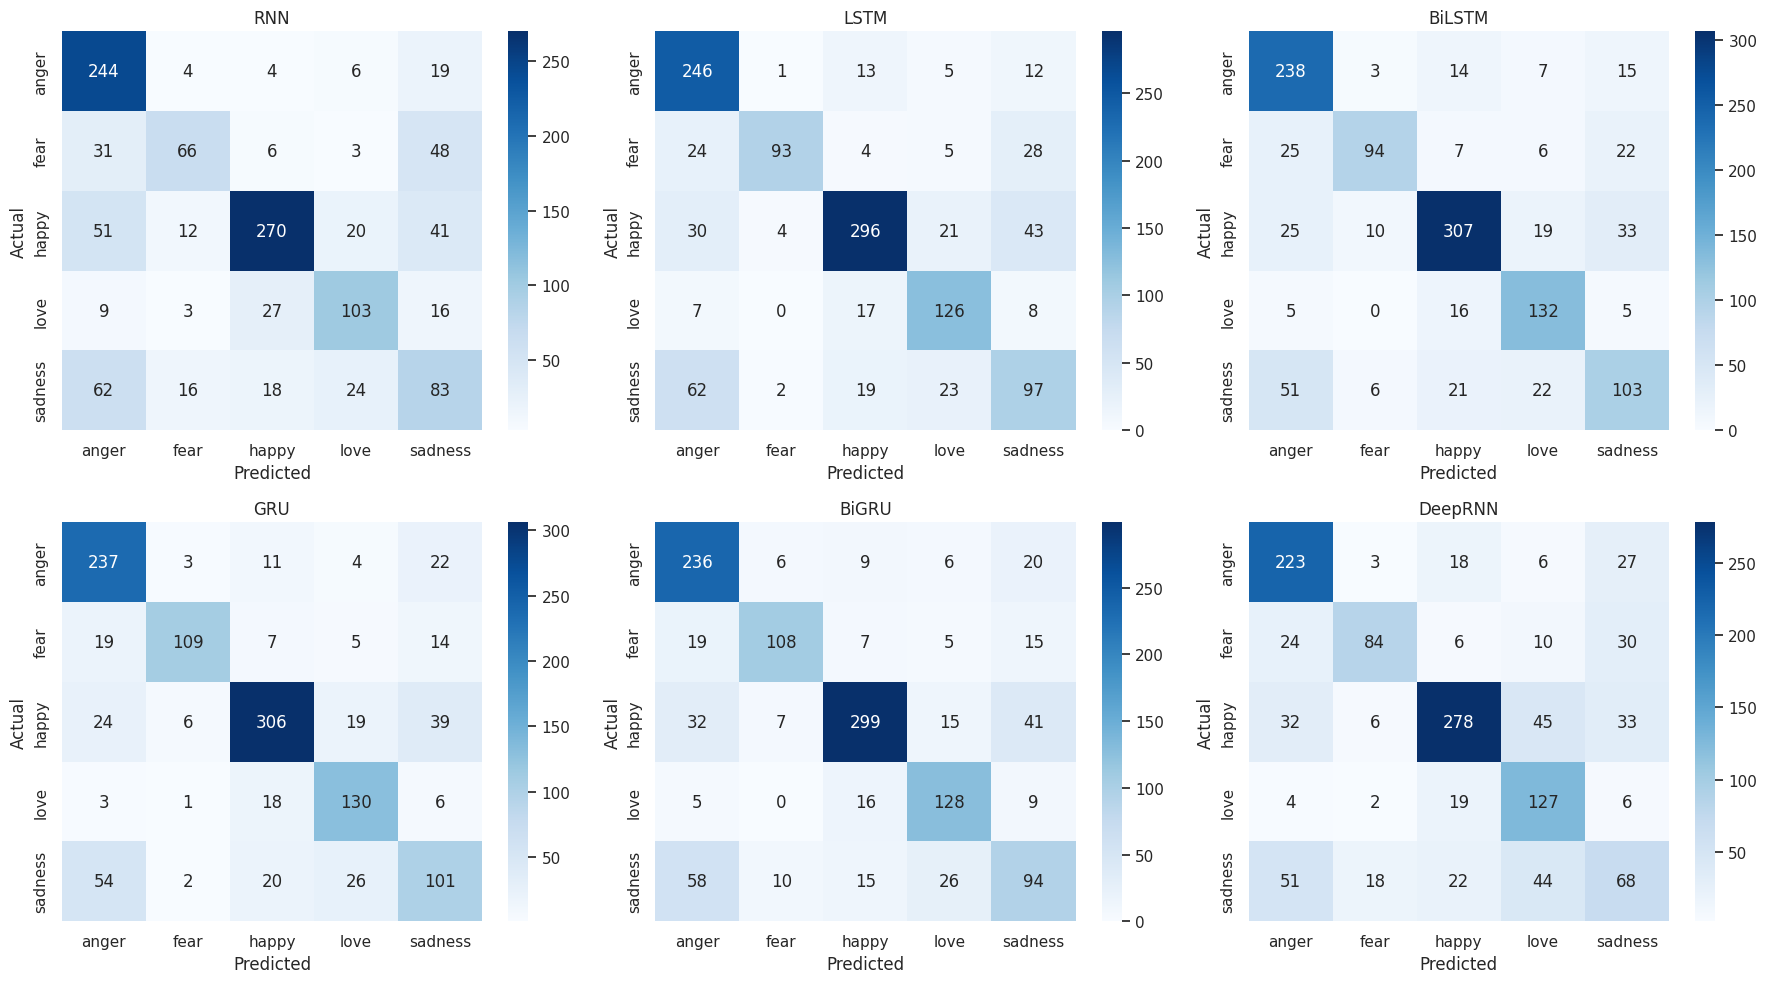

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.heatmap(cms["RNN"], annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[0, 0]); axes[0, 0].set_title("RNN")
sns.heatmap(cms["LSTM"], annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[0, 1]); axes[0, 1].set_title("LSTM")
sns.heatmap(cms["BiLSTM"], annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[0, 2]); axes[0, 2].set_title("BiLSTM")
sns.heatmap(cms["GRU"], annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[1, 0]); axes[1, 0].set_title("GRU")
sns.heatmap(cms["BiGRU"], annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[1, 1]); axes[1, 1].set_title("BiGRU")
sns.heatmap(cms["DeepRNN"], annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[1, 2]); axes[1, 2].set_title("DeepRNN")
for ax in axes.flatten():
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


## Cross Validation
- 5-Fold


In [24]:
if RUN_CV:
    all_raw = work_df["tweet"].astype(str).tolist()
    all_clean = work_df["clean_tweet"].astype(str).tolist()
    all_y = work_df["label_id"].values
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

    def build_aux_features_with_patterns(raw_texts, clean_texts, emo_pos_pattern, emo_neg_pattern):
        rows = []
        for raw, clean in zip(raw_texts, clean_texts):
            raw_text = str(raw)
            raw_lower = raw_text.lower()
            clean_text = str(clean)
            tokens = clean_text.split()
            lex_tokens = [t for t in tokens if t not in {"__excl__", "__ques__"}]

            excl_count = float(raw_text.count("!"))
            ques_count = float(raw_text.count("?"))
            cap_count = float(sum(ch.isupper() for ch in raw_text))
            alpha_count = float(sum(ch.isalpha() for ch in raw_text))
            upper_ratio = float(cap_count / max(alpha_count, 1.0))
            char_len = float(len(raw_text))
            tok_len = float(len(lex_tokens))
            pos_marker_cnt = float(tokens.count("__excl__"))
            ques_marker_cnt = float(tokens.count("__ques__"))
            emo_pos_cnt = float(len(emo_pos_pattern.findall(raw_lower)))
            emo_neg_cnt = float(len(emo_neg_pattern.findall(raw_lower)))
            inset_pos_score = float(sum(inset_pos.get(t, 0.0) for t in lex_tokens))
            inset_neg_score = float(sum(abs(inset_neg.get(t, 0.0)) for t in lex_tokens))
            inset_pos_hits = float(sum(1 for t in lex_tokens if t in inset_pos))
            inset_neg_hits = float(sum(1 for t in lex_tokens if t in inset_neg))
            rows.append([
                excl_count, ques_count, cap_count, upper_ratio, char_len, tok_len,
                pos_marker_cnt, ques_marker_cnt, emo_pos_cnt, emo_neg_cnt,
                inset_pos_score, inset_neg_score, inset_pos_hits, inset_neg_hits
            ])
        return np.asarray(rows, dtype=np.float32)

    def build_cv_embedding_matrix(tokenizer_cv, vocab_size_cv, unk_idx_cv, train_texts):
        needed_words = {w for w, i in tokenizer_cv.word_index.items() if 0 < i < vocab_size_cv}
        emb = np.zeros((vocab_size_cv, EMBED_DIM), dtype=np.float32)
        unk_vec = np.random.normal(loc=0.0, scale=0.05, size=(EMBED_DIM,)).astype(np.float32)
        emb[unk_idx_cv] = unk_vec
        loaded = 0
        if PRETRAINED_VEC_PATH.exists():
            with open(PRETRAINED_VEC_PATH, "r", encoding="utf-8", errors="ignore") as f:
                first_line = f.readline().rstrip("\n")
                parts = first_line.split(" ")
                has_header = len(parts) == 2 and parts[0].isdigit() and parts[1].isdigit()
                if not has_header:
                    vals = first_line.split()
                    if len(vals) == EMBED_DIM + 1 and vals[0] in needed_words:
                        emb[tokenizer_cv.word_index[vals[0]]] = np.asarray(vals[1:], dtype=np.float32)
                        loaded += 1
                for line in f:
                    vals = line.rstrip("\n").split(" ")
                    if len(vals) != EMBED_DIM + 1:
                        continue
                    w = vals[0]
                    idx = tokenizer_cv.word_index.get(w)
                    if idx is None or idx >= vocab_size_cv:
                        continue
                    emb[idx] = np.asarray(vals[1:], dtype=np.float32)
                    loaded += 1
        else:
            fold_sentences = [txt.split() for txt in train_texts]
            ft_cv = FastText(vector_size=EMBED_DIM, window=5, min_count=1, workers=os.cpu_count() or 2, sg=1, epochs=12, seed=SEED)
            ft_cv.build_vocab(fold_sentences)
            ft_cv.train(fold_sentences, total_examples=len(fold_sentences), epochs=ft_cv.epochs)
            for w, idx in tokenizer_cv.word_index.items():
                if idx >= vocab_size_cv or idx == 0:
                    continue
                try:
                    emb[idx] = ft_cv.wv[w]
                    loaded += 1
                except Exception:
                    emb[idx] = unk_vec
            del ft_cv
        for _, idx in tokenizer_cv.word_index.items():
            if idx >= vocab_size_cv or idx == 0:
                continue
            if not np.any(emb[idx]):
                emb[idx] = unk_vec
        return emb, loaded

    def build_cv_model(model_name, vocab_size_cv, aux_dim_cv, emb_matrix_cv):
        seq_input = Input(shape=(MAX_LEN,), name=f"{model_name}_seq_input")
        aux_input = Input(shape=(aux_dim_cv,), name=f"{model_name}_aux_input")
        e = Embedding(vocab_size_cv, EMBED_DIM, weights=[emb_matrix_cv], trainable=False, mask_zero=True)(seq_input)
        if model_name == "RNN":
            x = SimpleRNN(64, dropout=0.2)(e)
        elif model_name == "LSTM":
            x = LSTM(64, dropout=0.2)(e)
        elif model_name == "BiLSTM":
            x = Bidirectional(LSTM(64, dropout=0.2))(e)
        elif model_name == "GRU":
            x = GRU(64, dropout=0.2)(e)
        elif model_name == "BiGRU":
            x = Bidirectional(GRU(64, dropout=0.2))(e)
        elif model_name == "DeepRNN":
            x = SimpleRNN(64, return_sequences=True, dropout=0.2)(e)
            x = SimpleRNN(32, dropout=0.2)(x)
        else:
            raise ValueError(f"Unsupported CV model: {model_name}. Allowed: RNN, LSTM, BiLSTM, GRU, BiGRU, DeepRNN")
        x = Dense(96, activation="relu")(x)
        x = Dropout(0.3)(x)
        z = Dense(32, activation="relu")(aux_input)
        z = Dropout(0.1)(z)
        h = Concatenate()([x, z])
        h = Dense(64, activation="relu")(h)
        h = Dropout(0.2)(h)
        out = Dense(num_classes, activation="softmax")(h)
        m = Model(inputs=[seq_input, aux_input], outputs=out, name=f"{model_name}_cv")
        return compile_model(m)

    cv_rows = []
    cv_best_meta = []
    for model_name in CV_MODELS:
        fold_scores = []
        best_fold_f1 = -1.0
        best_fold_id = -1
        print(f"\n===== CV Start: {model_name} =====")
        for fold_id, (tr_idx, va_idx) in enumerate(skf.split(all_clean, all_y), start=1):
            tf.keras.backend.clear_session()
            gc.collect()

            tr_raw = [all_raw[i] for i in tr_idx]
            va_raw = [all_raw[i] for i in va_idx]
            tr_clean = [all_clean[i] for i in tr_idx]
            va_clean = [all_clean[i] for i in va_idx]
            y_tr = all_y[tr_idx]
            y_va = all_y[va_idx]

            tokenizer_cv = Tokenizer(num_words=MAX_WORDS, oov_token="<UNK>")
            tokenizer_cv.fit_on_texts(tr_clean)
            tr_seq = tokenizer_cv.texts_to_sequences(tr_clean)
            va_seq = tokenizer_cv.texts_to_sequences(va_clean)
            X_tr_pad = pad_sequences(tr_seq, maxlen=MAX_LEN, padding="post", truncating="post")
            X_va_pad = pad_sequences(va_seq, maxlen=MAX_LEN, padding="post", truncating="post")
            vocab_size_cv = min(MAX_WORDS, len(tokenizer_cv.word_index) + 1)
            unk_idx_cv = tokenizer_cv.word_index.get("<UNK>", 1)

            _, auto_pos_cv, auto_neg_cv = discover_emoticons(tr_raw, min_freq=2)
            pos_cv = sorted(set(SEED_POS_EMOTICONS).union(auto_pos_cv))
            neg_cv = sorted(set(SEED_NEG_EMOTICONS).union(auto_neg_cv))
            emo_pos_pattern = re.compile("|".join(re.escape(e) for e in pos_cv)) if pos_cv else re.compile(r"$^")
            emo_neg_pattern = re.compile("|".join(re.escape(e) for e in neg_cv)) if neg_cv else re.compile(r"$^")

            X_tr_aux = build_aux_features_with_patterns(tr_raw, tr_clean, emo_pos_pattern, emo_neg_pattern)
            X_va_aux = build_aux_features_with_patterns(va_raw, va_clean, emo_pos_pattern, emo_neg_pattern)
            mu = X_tr_aux.mean(axis=0)
            sigma = X_tr_aux.std(axis=0)
            sigma[sigma == 0] = 1.0
            X_tr_aux = (X_tr_aux - mu) / sigma
            X_va_aux = (X_va_aux - mu) / sigma

            emb_cv, loaded_cv = build_cv_embedding_matrix(tokenizer_cv, vocab_size_cv, unk_idx_cv, tr_clean)
            cls_cv = np.unique(y_tr)
            w_cv = compute_class_weight(class_weight="balanced", classes=cls_cv, y=y_tr)
            w_cv = {int(k): float(v) for k, v in zip(cls_cv, w_cv)}

            model_cv = build_cv_model(model_name, vocab_size_cv, X_tr_aux.shape[1], emb_cv)
            val_f1_cb = ValF1Callback([X_va_pad, X_va_aux], y_va, batch_size=256)
            cbs = [
                EarlyStopping(monitor="val_f1", mode="max", patience=max(1, PATIENCE), restore_best_weights=True),
                ReduceLROnPlateau(monitor="val_f1", mode="max", factor=0.5, patience=1, min_lr=1e-6),
                val_f1_cb,
            ]
            if TqdmCallback is not None:
                cbs.append(TqdmCallback(verbose=1))

            model_cv.fit(
                [X_tr_pad, X_tr_aux], y_tr,
                validation_data=([X_va_pad, X_va_aux], y_va),
                epochs=CV_EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=w_cv,
                callbacks=cbs,
                verbose=0 if TqdmCallback is not None else 1,
            )
            pred_va = np.argmax(model_cv.predict([X_va_pad, X_va_aux], batch_size=256, verbose=0), axis=1)
            fold_f1 = float(f1_score(y_va, pred_va, average="macro"))
            fold_scores.append(fold_f1)
            if fold_f1 > best_fold_f1:
                best_fold_f1 = fold_f1
                best_fold_id = fold_id
                cv_model_path = MODEL_DIR / f"{model_name.lower()}_cv_best.keras"
                model_cv.save(cv_model_path)
                with open(ARTIFACT_DIR / f"{model_name.lower()}_cv_best_tokenizer.json", "w", encoding="utf-8") as f:
                    f.write(tokenizer_cv.to_json())
                np.save(ARTIFACT_DIR / f"{model_name.lower()}_cv_best_aux_mu.npy", mu)
                np.save(ARTIFACT_DIR / f"{model_name.lower()}_cv_best_aux_sigma.npy", sigma)
            print(f"[{model_name}] fold-{fold_id} macro_f1={fold_f1:.4f} | loaded_vec={loaded_cv}")

        cv_rows.append({
            "model": model_name,
            "cv_folds": CV_FOLDS,
            "cv_macro_f1_mean": float(np.mean(fold_scores)),
            "cv_macro_f1_std": float(np.std(fold_scores)),
            "paper_macro_f1": PAPER_MACRO_F1
        })
        cv_best_meta.append({
            "model": model_name,
            "best_fold": int(best_fold_id),
            "best_fold_macro_f1": float(best_fold_f1),
            "best_model_path": str(MODEL_DIR / f"{model_name.lower()}_cv_best.keras"),
            "tokenizer_path": str(ARTIFACT_DIR / f"{model_name.lower()}_cv_best_tokenizer.json"),
            "aux_mu_path": str(ARTIFACT_DIR / f"{model_name.lower()}_cv_best_aux_mu.npy"),
            "aux_sigma_path": str(ARTIFACT_DIR / f"{model_name.lower()}_cv_best_aux_sigma.npy"),
        })
        print(f"[{model_name}] CV mean={np.mean(fold_scores):.4f} std={np.std(fold_scores):.4f}")

    cv_df = pd.DataFrame(cv_rows).sort_values("cv_macro_f1_mean", ascending=False).reset_index(drop=True)
    display(cv_df)
    cv_df.to_csv(ARTIFACT_DIR / "cv_top_models.csv", index=False)
    with open(ARTIFACT_DIR / "cv_best_models.json", "w", encoding="utf-8") as f:
        json.dump(cv_best_meta, f, indent=2)
else:
    print("RUN_CV=False, skip 5-fold CV block.")



===== CV Start: BiGRU =====


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

[BiGRU] fold-1 macro_f1=0.7432 | loaded_vec=15882


0epoch [00:00, ?epoch/s]

...

[LSTM] fold-4 macro_f1=0.6918 | loaded_vec=15747


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

[LSTM] fold-5 macro_f1=0.7022 | loaded_vec=15857
[LSTM] CV mean=0.7025 std=0.0160


,model,cv_folds,cv_macro_f1_mean,cv_macro_f1_std,paper_macro_f1
0,GRU,5,0.721725,0.010581,0.6973
1,BiGRU,5,0.717160,0.014013,0.6973
2,BiLSTM,5,0.712545,0.014214,0.6973
3,LSTM,5,0.702538,0.016041,0.6973


## Save


In [25]:
with open(ARTIFACT_DIR / "tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())
np.save(ARTIFACT_DIR / "embedding_matrix.npy", embedding_matrix)
np.save(ARTIFACT_DIR / "label_classes.npy", label_encoder.classes_)
np.save(ARTIFACT_DIR / "aux_mu.npy", aux_mu)
np.save(ARTIFACT_DIR / "aux_sigma.npy", aux_sigma)
with open(ARTIFACT_DIR / "aux_feature_names.json", "w", encoding="utf-8") as f:
    json.dump(AUX_FEATURE_NAMES, f, indent=2)

config = {
    "seed": SEED,
    "max_words": MAX_WORDS,
    "max_len": MAX_LEN,
    "embed_dim": EMBED_DIM,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LR,
    "weight_decay": WEIGHT_DECAY,
    "clipnorm": CLIPNORM,
    "input_path": str(DATA_PATH),
    "output_path": str(OUTPUT_ROOT),
    "paper_macro_f1": PAPER_MACRO_F1,
    "models": ["RNN", "LSTM", "BiLSTM", "GRU", "BiGRU", "DeepRNN"],
}
with open(ARTIFACT_DIR / "training_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Saved to:", ARTIFACT_DIR)


Saved to: /kaggle/working/artifacts_rnn


In [26]:
for _name in [
    "df", "work_df", "X_train_pad", "X_val_pad", "X_train_aux", "X_val_aux",
    "X_train_seq", "X_val_seq", "ft_model"
]:
    if _name in globals():
        del globals()[_name]
gc.collect()
print("Memory cleaned.")


Memory cleaned.
